In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from medmnist import PathMNIST

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("MedVision V2 libraries imported successfully!")

MedVision V2 libraries imported successfully!


In [2]:
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_ROOT = PROJECT_ROOT / "data" / "medmnist"
MODEL_DIR = PROJECT_ROOT / "models"
FIGURE_DIR = PROJECT_ROOT / "docs" / "figures"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_ROOT)
print("Dataset directory:", DATA_ROOT)
print("Model directory:", MODEL_DIR)
print("Figure directory:", FIGURE_DIR)

Project directory: /Users/keonhowang/Desktop/MedVision
Dataset directory: /Users/keonhowang/Desktop/MedVision/data/medmnist
Model directory: /Users/keonhowang/Desktop/MedVision/models
Figure directory: /Users/keonhowang/Desktop/MedVision/docs/figures


In [3]:
if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

print("Selected device:", device)

Selected device: mps


In [4]:
train_dataset = PathMNIST(
    split="train",
    root=str(DATA_ROOT),
    download=False
)

val_dataset = PathMNIST(
    split="val",
    root=str(DATA_ROOT),
    download=False
)

test_dataset = PathMNIST(
    split="test",
    root=str(DATA_ROOT),
    download=False
)

print("All datasets loaded successfully!")
print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Testing samples:", len(test_dataset))

All datasets loaded successfully!
Training samples: 89996
Validation samples: 10004
Testing samples: 7180


In [5]:
class MedVisionDataset(Dataset):

    def __init__(self, medmnist_dataset, transform=None):
        self.images = medmnist_dataset.imgs
        self.labels = medmnist_dataset.labels
        self.transform = transform

    def __len__(self):
        return len(self.images)

    def __getitem__(self, index):

        image = self.images[index]
        image = torch.from_numpy(image)
        image = image.permute(2, 0, 1)
        image = image.float() / 255.0

        if self.transform:
            image = self.transform(image)

        label = torch.tensor(
            int(self.labels[index][0]),
            dtype=torch.long
        )

        return image, label

In [6]:
train_data = MedVisionDataset(train_dataset)
val_data = MedVisionDataset(val_dataset)
test_data = MedVisionDataset(test_dataset)

sample_image, sample_label = train_data[0]

print("Image shape:", sample_image.shape)
print("Image data type:", sample_image.dtype)
print("Label:", sample_label.item())
print("Minimum pixel value:", sample_image.min().item())
print("Maximum pixel value:", sample_image.max().item())

Image shape: torch.Size([3, 28, 28])
Image data type: torch.float32
Label: 0
Minimum pixel value: 0.6431372761726379
Maximum pixel value: 0.8941176533699036


In [7]:
BATCH_SIZE = 64

train_loader = DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_data,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_data,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

Training batches: 1407
Validation batches: 157
Testing batches: 113


In [8]:
class MedVisionCNNV2(nn.Module):

    def __init__(self, num_classes=9):

        super(MedVisionCNNV2, self).__init__()

        # First convolutional block
        self.conv1 = nn.Conv2d(
            in_channels=3,
            out_channels=32,
            kernel_size=3,
            padding=1
        )

        self.bn1 = nn.BatchNorm2d(32)

        # Second convolutional block
        self.conv2 = nn.Conv2d(
            in_channels=32,
            out_channels=64,
            kernel_size=3,
            padding=1
        )

        self.bn2 = nn.BatchNorm2d(64)

        # Third convolutional block
        self.conv3 = nn.Conv2d(
            in_channels=64,
            out_channels=128,
            kernel_size=3,
            padding=1
        )

        self.bn3 = nn.BatchNorm2d(128)

        # Pooling
        self.pool = nn.MaxPool2d(
            kernel_size=2,
            stride=2
        )

        self.global_pool = nn.AdaptiveAvgPool2d((1, 1))

        # Dropout
        self.dropout = nn.Dropout(p=0.4)

        # Classifier
        self.fc1 = nn.Linear(128, 128)
        self.fc2 = nn.Linear(128, num_classes)


    def forward(self, x):

        # First block
        x = self.conv1(x)
        x = self.bn1(x)
        x = F.relu(x)
        x = self.pool(x)

        # Second block
        x = self.conv2(x)
        x = self.bn2(x)
        x = F.relu(x)
        x = self.pool(x)

        # Third block
        x = self.conv3(x)
        x = self.bn3(x)
        x = F.relu(x)

        # Global average pooling
        x = self.global_pool(x)

        # Flatten
        x = torch.flatten(x, start_dim=1)

        # Classifier
        x = self.fc1(x)
        x = F.relu(x)
        x = self.dropout(x)

        x = self.fc2(x)

        return x

In [9]:
NUM_CLASSES = 9

model_v2 = MedVisionCNNV2(
    num_classes=NUM_CLASSES
).to(device)

print(model_v2)

MedVisionCNNV2(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (global_pool): AdaptiveAvgPool2d(output_size=(1, 1))
  (dropout): Dropout(p=0.4, inplace=False)
  (fc1): Linear(in_features=128, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=9, bias=True)
)


In [10]:
total_params = sum(
    parameter.numel()
    for parameter in model_v2.parameters()
    if parameter.requires_grad
)

print(f"Total trainable parameters: {total_params:,}")

Total trainable parameters: 111,369


In [11]:
sample_images, sample_labels = next(iter(train_loader))

sample_images = sample_images.to(device)

model_v2.eval()

with torch.no_grad():
    sample_outputs = model_v2(sample_images)

print("Input shape:", sample_images.shape)
print("Output shape:", sample_outputs.shape)
print("Expected output shape: [64, 9]")

Input shape: torch.Size([64, 3, 28, 28])
Output shape: torch.Size([64, 9])
Expected output shape: [64, 9]


In [12]:
train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=15)
])

print("Training augmentation configured successfully!")

Training augmentation configured successfully!


In [13]:
train_data = MedVisionDataset(
    train_dataset,
    transform=train_transform
)

val_data = MedVisionDataset(
    val_dataset,
    transform=None
)

test_data = MedVisionDataset(
    test_dataset,
    transform=None
)

print("Training dataset augmentation applied!")
print("Validation dataset remains unchanged.")
print("Test dataset remains unchanged.")

Training dataset augmentation applied!
Validation dataset remains unchanged.
Test dataset remains unchanged.


In [14]:
train_loader = DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_data,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_data,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

Training batches: 1407
Validation batches: 157
Testing batches: 113


In [16]:
# Get one sample from the dataset
sample_image, sample_label = train_dataset[0]

# Convert PIL Image to NumPy array
sample_image = np.array(sample_image)

# Convert NumPy array to PyTorch tensor
original_image = torch.from_numpy(sample_image)

# Change image format from HWC to CHW
original_image = original_image.permute(2, 0, 1).float() / 255.0

print("Original image type:", type(sample_image))
print("Tensor shape:", original_image.shape)
print("Label:", sample_label)

Original image type: <class 'numpy.ndarray'>
Tensor shape: torch.Size([3, 28, 28])
Label: [0]


In [19]:
class_counts = np.bincount(
    train_dataset.labels.flatten(),
    minlength=NUM_CLASSES
)

class_distribution = pd.DataFrame({
    "Class": class_names,
    "Count": class_counts
})

print(class_distribution)

                                  Class  Count
0                               Adipose   9366
1                            Background   9509
2                                Debris  10360
3                           Lymphocytes  10401
4                                 Mucus   8006
5                         Smooth Muscle  12182
6                   Normal Colon Mucosa   7886
7              Cancer-associated Stroma   9401
8  Colorectal Adenocarcinoma Epithelium  12885


In [20]:
criterion_v2 = nn.CrossEntropyLoss()

LEARNING_RATE = 0.001

optimizer_v2 = torch.optim.Adam(
    model_v2.parameters(),
    lr=LEARNING_RATE
)

print("V2 loss function and optimizer initialized!")
print("Learning rate:", LEARNING_RATE)

V2 loss function and optimizer initialized!
Learning rate: 0.001


In [22]:
class RandomRightAngleRotation:

    def __call__(self, image):
        k = torch.randint(0, 4, (1,)).item()

        return torch.rot90(
            image,
            k,
            dims=(1, 2)
        )


train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    RandomRightAngleRotation()
])

print("Training augmentation pipeline created!")

Training augmentation pipeline created!


In [23]:
train_data = MedVisionDataset(
    train_dataset,
    transform=train_transform
)

val_data = MedVisionDataset(
    val_dataset,
    transform=None
)

test_data = MedVisionDataset(
    test_dataset,
    transform=None
)

print("Augmented training dataset created!")
print("Validation and test datasets remain unchanged.")

Augmented training dataset created!
Validation and test datasets remain unchanged.


In [24]:
train_loader = DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_data,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_data,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

Training batches: 1407
Validation batches: 157
Testing batches: 113


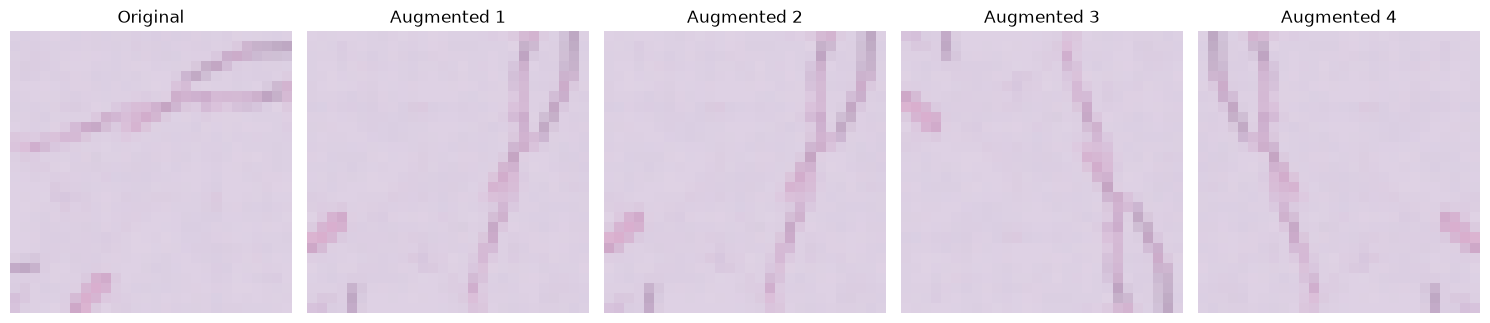

In [25]:
original_image, original_label = MedVisionDataset(
    train_dataset
)[0]

augmented_images = [
    train_data[0][0]
    for _ in range(4)
]

fig, axes = plt.subplots(1, 5, figsize=(15, 4))

axes[0].imshow(original_image.permute(1, 2, 0))
axes[0].set_title("Original")

for i, image in enumerate(augmented_images):
    axes[i + 1].imshow(image.permute(1, 2, 0))
    axes[i + 1].set_title(f"Augmented {i + 1}")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [26]:
train_labels = train_dataset.labels.flatten()

class_counts = np.bincount(
    train_labels,
    minlength=NUM_CLASSES
)

print("Training class distribution:")

for i, count in enumerate(class_counts):
    print(f"{class_names[i]}: {count}")

Training class distribution:
Adipose: 9366
Background: 9509
Debris: 10360
Lymphocytes: 10401
Mucus: 8006
Smooth Muscle: 12182
Normal Colon Mucosa: 7886
Cancer-associated Stroma: 9401
Colorectal Adenocarcinoma Epithelium: 12885


In [27]:
class_weights = len(train_labels) / (
    NUM_CLASSES * class_counts
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32
).to(device)

print("Class weights:")

for i, weight in enumerate(class_weights):
    print(f"{class_names[i]}: {weight.item():.4f}")

Class weights:
Adipose: 1.0676
Background: 1.0516
Debris: 0.9652
Lymphocytes: 0.9614
Mucus: 1.2490
Smooth Muscle: 0.8208
Normal Colon Mucosa: 1.2680
Cancer-associated Stroma: 1.0637
Colorectal Adenocarcinoma Epithelium: 0.7761


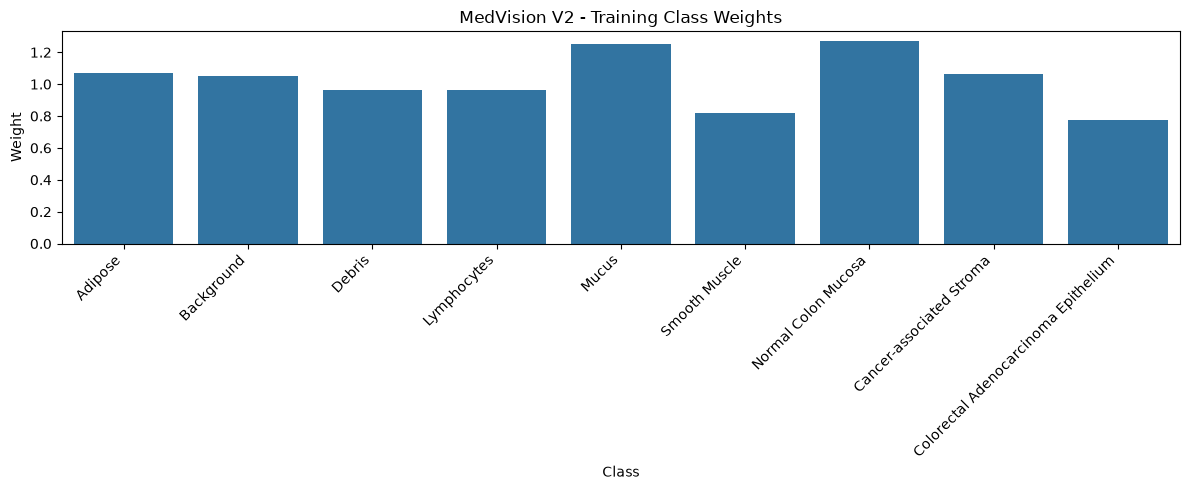

In [28]:
weights_df = pd.DataFrame({
    "Class": class_names,
    "Weight": class_weights.cpu().numpy()
})

plt.figure(figsize=(12, 5))

sns.barplot(
    data=weights_df,
    x="Class",
    y="Weight"
)

plt.title("MedVision V2 - Training Class Weights")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "v2_class_weights.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [29]:
torch.manual_seed(42)

model_v2 = MedVisionCNNV2(
    num_classes=NUM_CLASSES
).to(device)

print("MedVisionCNNV2 initialized successfully!")

MedVisionCNNV2 initialized successfully!


In [30]:
criterion_v2 = nn.CrossEntropyLoss(
    weight=class_weights
)

print("Weighted Cross Entropy Loss initialized!")

Weighted Cross Entropy Loss initialized!


In [31]:
LEARNING_RATE = 0.001

optimizer_v2 = torch.optim.Adam(
    model_v2.parameters(),
    lr=LEARNING_RATE
)

print("Adam optimizer initialized!")
print("Learning rate:", LEARNING_RATE)

Adam optimizer initialized!
Learning rate: 0.001


In [32]:
model_v2.train()

images, labels = next(iter(train_loader))

images = images.to(device)
labels = labels.to(device)

optimizer_v2.zero_grad()

outputs = model_v2(images)

loss = criterion_v2(outputs, labels)

loss.backward()

optimizer_v2.step()

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)
print("Training loss:", loss.item())
print("Training smoke test completed successfully!")

Input shape: torch.Size([64, 3, 28, 28])
Output shape: torch.Size([64, 9])
Training loss: 2.200498104095459
Training smoke test completed successfully!


In [33]:
def train_one_epoch_v2(model, loader, criterion, optimizer, device):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item() * images.size(0)

        _, predictions = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predictions == labels).sum().item()

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy


print("V2 training function defined successfully!")

V2 training function defined successfully!


In [34]:
def evaluate_model_v2(model, loader, criterion, device):

    model.eval()

    running_loss = 0.0
    all_predictions = []
    all_labels = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            _, predictions = torch.max(outputs, 1)

            all_predictions.extend(
                predictions.cpu().numpy()
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

    epoch_loss = running_loss / len(loader.dataset)

    epoch_accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    epoch_macro_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro"
    )

    return epoch_loss, epoch_accuracy, epoch_macro_f1


print("V2 evaluation function defined successfully!")

V2 evaluation function defined successfully!


In [35]:
torch.manual_seed(42)

model_v2 = MedVisionCNNV2(
    num_classes=NUM_CLASSES
).to(device)

criterion_v2 = nn.CrossEntropyLoss(
    weight=class_weights
)

optimizer_v2 = torch.optim.Adam(
    model_v2.parameters(),
    lr=LEARNING_RATE
)

print("V2 model reset successfully!")
print("Optimizer reset successfully!")
print("Ready for full training.")

V2 model reset successfully!
Optimizer reset successfully!
Ready for full training.


In [36]:
EPOCHS = 10

history_v2 = []

best_val_f1_v2 = 0.0

MODEL_PATH_V2 = MODEL_DIR / "medvision_cnn_v2.pth"

for epoch in range(EPOCHS):

    train_loss, train_accuracy = train_one_epoch_v2(
        model_v2,
        train_loader,
        criterion_v2,
        optimizer_v2,
        device
    )

    val_loss, val_accuracy, val_macro_f1 = evaluate_model_v2(
        model_v2,
        val_loader,
        criterion_v2,
        device
    )

    history_v2.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "val_loss": val_loss,
        "val_accuracy": val_accuracy,
        "val_macro_f1": val_macro_f1
    })

    if val_macro_f1 > best_val_f1_v2:

        best_val_f1_v2 = val_macro_f1

        torch.save(
            model_v2.state_dict(),
            MODEL_PATH_V2
        )

    print(
        f"Epoch [{epoch + 1}/{EPOCHS}] "
        f"Train Loss: {train_loss:.4f} "
        f"Train Acc: {train_accuracy:.4f} "
        f"Val Loss: {val_loss:.4f} "
        f"Val Acc: {val_accuracy:.4f} "
        f"Val Macro F1: {val_macro_f1:.4f}"
    )

print("\nV2 training completed!")
print(f"Best Validation Macro F1: {best_val_f1_v2:.4f}")
print("Best model saved to:", MODEL_PATH_V2)

Epoch [1/10] Train Loss: 0.6010 Train Acc: 0.7823 Val Loss: 2.6997 Val Acc: 0.5546 Val Macro F1: 0.5014
Epoch [2/10] Train Loss: 0.3546 Train Acc: 0.8738 Val Loss: 0.8650 Val Acc: 0.7177 Val Macro F1: 0.6963
Epoch [3/10] Train Loss: 0.2855 Train Acc: 0.9001 Val Loss: 1.3887 Val Acc: 0.5936 Val Macro F1: 0.5858
Epoch [4/10] Train Loss: 0.2422 Train Acc: 0.9151 Val Loss: 3.0761 Val Acc: 0.4711 Val Macro F1: 0.4676
Epoch [5/10] Train Loss: 0.2150 Train Acc: 0.9261 Val Loss: 1.2293 Val Acc: 0.7011 Val Macro F1: 0.6828
Epoch [6/10] Train Loss: 0.1981 Train Acc: 0.9326 Val Loss: 0.2997 Val Acc: 0.9028 Val Macro F1: 0.8991
Epoch [7/10] Train Loss: 0.1797 Train Acc: 0.9383 Val Loss: 4.4053 Val Acc: 0.4914 Val Macro F1: 0.4430
Epoch [8/10] Train Loss: 0.1723 Train Acc: 0.9408 Val Loss: 0.9342 Val Acc: 0.7572 Val Macro F1: 0.7636
Epoch [9/10] Train Loss: 0.1591 Train Acc: 0.9450 Val Loss: 1.0877 Val Acc: 0.6412 Val Macro F1: 0.6085
Epoch [10/10] Train Loss: 0.1491 Train Acc: 0.9492 Val Loss: 7.2

In [37]:
history_v2_df = pd.DataFrame(history_v2)

print(history_v2_df.round(4).to_string(index=False))

best_epoch_v2 = (
    history_v2_df["val_macro_f1"].idxmax() + 1
)

print("\nBest epoch:", best_epoch_v2)
print(
    "Best validation Macro F1:",
    history_v2_df["val_macro_f1"].max()
)

 epoch  train_loss  train_accuracy  val_loss  val_accuracy  val_macro_f1
     1      0.6010          0.7823    2.6997        0.5546        0.5014
     2      0.3546          0.8738    0.8650        0.7177        0.6963
     3      0.2855          0.9001    1.3887        0.5936        0.5858
     4      0.2422          0.9151    3.0761        0.4711        0.4676
     5      0.2150          0.9261    1.2293        0.7011        0.6828
     6      0.1981          0.9326    0.2997        0.9028        0.8991
     7      0.1797          0.9383    4.4053        0.4914        0.4430
     8      0.1723          0.9408    0.9342        0.7572        0.7636
     9      0.1591          0.9450    1.0877        0.6412        0.6085
    10      0.1491          0.9492    7.2454        0.2931        0.2128

Best epoch: 6
Best validation Macro F1: 0.8991328504925158


In [38]:
# Reload the best saved V2 model (epoch 6)
model_v2.load_state_dict(
    torch.load(
        MODEL_PATH_V2,
        map_location=device,
        weights_only=True
    )
)

model_v2.eval()

# Evaluate the same validation dataset three times
for run in range(1, 4):
    val_loss, val_accuracy, val_macro_f1 = evaluate_model_v2(
        model_v2,
        val_loader,
        criterion_v2,
        device
    )

    print(
        f"Run {run}: "
        f"Loss = {val_loss:.4f}, "
        f"Accuracy = {val_accuracy:.4f}, "
        f"Macro F1 = {val_macro_f1:.4f}"
    )

print("\nValidation transform:", val_data.transform)
print("Validation loader shuffle:", val_loader.shuffle if hasattr(val_loader, "shuffle") else "Check DataLoader configuration")

Run 1: Loss = 0.2997, Accuracy = 0.9028, Macro F1 = 0.8991
Run 2: Loss = 0.2997, Accuracy = 0.9028, Macro F1 = 0.8991
Run 3: Loss = 0.2997, Accuracy = 0.9028, Macro F1 = 0.8991

Validation transform: None
Validation loader shuffle: Check DataLoader configuration


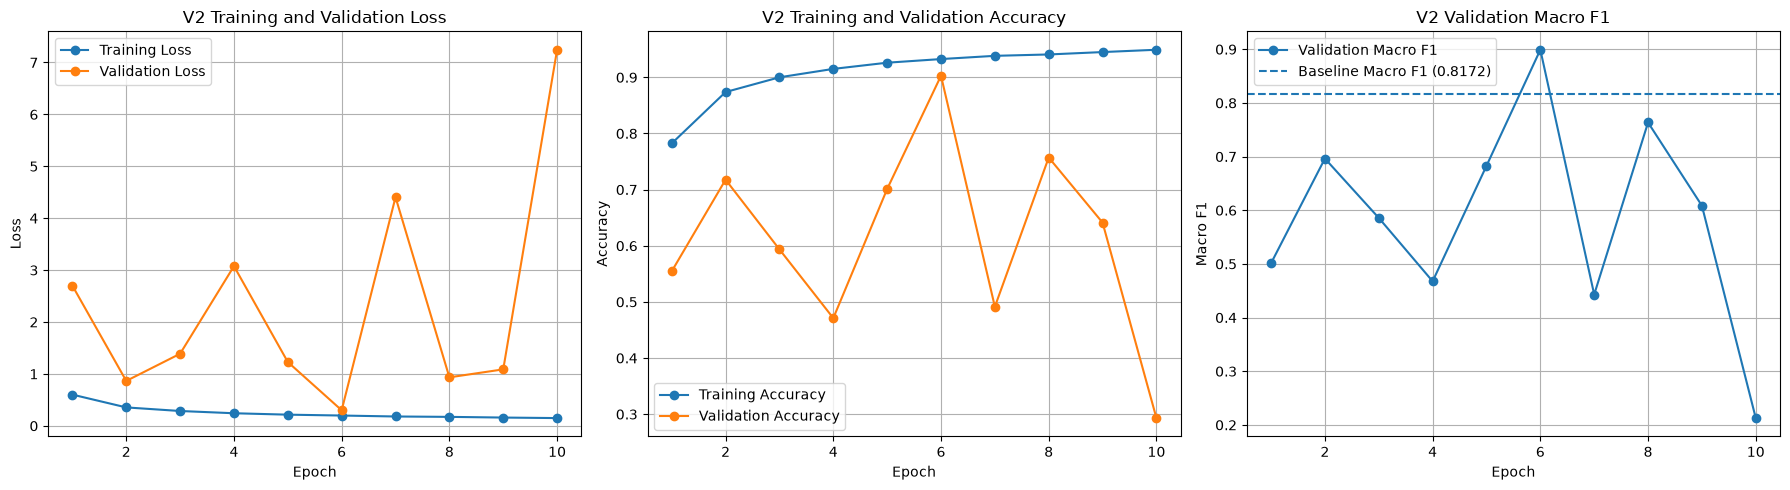

Learning curves saved successfully!


In [39]:
# Create a 1x3 figure
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

epochs = history_v2_df["epoch"]

# 1. Loss
axes[0].plot(epochs, history_v2_df["train_loss"], marker="o", label="Training Loss")
axes[0].plot(epochs, history_v2_df["val_loss"], marker="o", label="Validation Loss")
axes[0].set_title("V2 Training and Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

# 2. Accuracy
axes[1].plot(epochs, history_v2_df["train_accuracy"], marker="o", label="Training Accuracy")
axes[1].plot(epochs, history_v2_df["val_accuracy"], marker="o", label="Validation Accuracy")
axes[1].set_title("V2 Training and Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True)

# 3. Macro F1
axes[2].plot(epochs, history_v2_df["val_macro_f1"], marker="o", label="Validation Macro F1")
axes[2].axhline(
    y=0.8172,
    linestyle="--",
    label="Baseline Macro F1 (0.8172)"
)
axes[2].set_title("V2 Validation Macro F1")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("Macro F1")
axes[2].legend()
axes[2].grid(True)

plt.tight_layout()

# Save the figure
plt.savefig(
    FIGURE_DIR / "v2_learning_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Learning curves saved successfully!")

In [40]:
print("Validation sampler:", type(val_loader.sampler).__name__)
print("Validation dataset size:", len(val_loader.dataset))
print("Validation batches:", len(val_loader))

Validation sampler: SequentialSampler
Validation dataset size: 10004
Validation batches: 157


In [41]:
LEARNING_RATE_V21 = 0.0003
EPOCHS_V21 = 10

MODEL_PATH_V21 = MODEL_DIR / "medvision_cnn_v2_lr0003.pth"

print("V2.1 Learning Rate:", LEARNING_RATE_V21)
print("V2.1 Epochs:", EPOCHS_V21)

V2.1 Learning Rate: 0.0003
V2.1 Epochs: 10


In [42]:
torch.manual_seed(42)

model_v21 = MedVisionCNNV2(num_classes=NUM_CLASSES).to(device)

criterion_v21 = nn.CrossEntropyLoss(weight=class_weights)

optimizer_v21 = torch.optim.Adam(
    model_v21.parameters(),
    lr=LEARNING_RATE_V21
)

print("V2.1 model initialized successfully!")
print("Optimizer:", optimizer_v21)

V2.1 model initialized successfully!
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0003
    maximize: False
    weight_decay: 0
)


In [43]:
history_v21 = []
best_val_f1_v21 = 0.0

for epoch in range(EPOCHS_V21):

    train_loss, train_accuracy = train_one_epoch_v2(
        model_v21,
        train_loader,
        criterion_v21,
        optimizer_v21,
        device
    )

    val_loss, val_accuracy, val_macro_f1 = evaluate_model_v2(
        model_v21,
        val_loader,
        criterion_v21,
        device
    )

    history_v21.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "val_loss": val_loss,
        "val_accuracy": val_accuracy,
        "val_macro_f1": val_macro_f1
    })

    if val_macro_f1 > best_val_f1_v21:
        best_val_f1_v21 = val_macro_f1

        torch.save(
            model_v21.state_dict(),
            MODEL_PATH_V21
        )

    print(
        f"Epoch [{epoch + 1}/{EPOCHS_V21}] "
        f"Train Loss: {train_loss:.4f} "
        f"Train Acc: {train_accuracy:.4f} "
        f"Val Loss: {val_loss:.4f} "
        f"Val Acc: {val_accuracy:.4f} "
        f"Val Macro F1: {val_macro_f1:.4f}"
    )

print("\nV2.1 training completed!")
print(f"Best Validation Macro F1: {best_val_f1_v21:.4f}")
print("Best model saved to:", MODEL_PATH_V21)

Epoch [1/10] Train Loss: 0.7038 Train Acc: 0.7516 Val Loss: 0.6488 Val Acc: 0.7531 Val Macro F1: 0.7363
Epoch [2/10] Train Loss: 0.4108 Train Acc: 0.8546 Val Loss: 0.8421 Val Acc: 0.7214 Val Macro F1: 0.7253
Epoch [3/10] Train Loss: 0.3352 Train Acc: 0.8810 Val Loss: 0.3517 Val Acc: 0.8711 Val Macro F1: 0.8733
Epoch [4/10] Train Loss: 0.2881 Train Acc: 0.8988 Val Loss: 0.2826 Val Acc: 0.9017 Val Macro F1: 0.9030
Epoch [5/10] Train Loss: 0.2594 Train Acc: 0.9099 Val Loss: 0.6168 Val Acc: 0.7980 Val Macro F1: 0.7890
Epoch [6/10] Train Loss: 0.2347 Train Acc: 0.9187 Val Loss: 0.5642 Val Acc: 0.8216 Val Macro F1: 0.8233
Epoch [7/10] Train Loss: 0.2166 Train Acc: 0.9244 Val Loss: 0.9614 Val Acc: 0.7073 Val Macro F1: 0.6866
Epoch [8/10] Train Loss: 0.2000 Train Acc: 0.9304 Val Loss: 0.2995 Val Acc: 0.8839 Val Macro F1: 0.8831
Epoch [9/10] Train Loss: 0.1872 Train Acc: 0.9347 Val Loss: 0.5098 Val Acc: 0.8263 Val Macro F1: 0.8057
Epoch [10/10] Train Loss: 0.1788 Train Acc: 0.9386 Val Loss: 0.2

In [44]:
history_v21_df = pd.DataFrame(history_v21)

print(history_v21_df.round(4).to_string(index=False))

best_epoch_v21 = history_v21_df["val_macro_f1"].idxmax() + 1

print("\nBest epoch:", best_epoch_v21)
print("Best validation Macro F1:", best_val_f1_v21)

 epoch  train_loss  train_accuracy  val_loss  val_accuracy  val_macro_f1
     1      0.7038          0.7516    0.6488        0.7531        0.7363
     2      0.4108          0.8546    0.8421        0.7214        0.7253
     3      0.3352          0.8810    0.3517        0.8711        0.8733
     4      0.2881          0.8988    0.2826        0.9017        0.9030
     5      0.2594          0.9099    0.6168        0.7980        0.7890
     6      0.2347          0.9187    0.5642        0.8216        0.8233
     7      0.2166          0.9244    0.9614        0.7073        0.6866
     8      0.2000          0.9304    0.2995        0.8839        0.8831
     9      0.1872          0.9347    0.5098        0.8263        0.8057
    10      0.1788          0.9386    0.2641        0.9033        0.9052

Best epoch: 10
Best validation Macro F1: 0.905150538735944


In [45]:
# Reload the best V2.1 checkpoint
model_v21.load_state_dict(
    torch.load(
        MODEL_PATH_V21,
        map_location=device,
        weights_only=True
    )
)

model_v21.eval()

# Evaluate the checkpoint three times
for run in range(1, 4):

    val_loss, val_accuracy, val_macro_f1 = evaluate_model_v2(
        model_v21,
        val_loader,
        criterion_v21,
        device
    )

    print(
        f"Run {run}: "
        f"Loss = {val_loss:.4f}, "
        f"Accuracy = {val_accuracy:.4f}, "
        f"Macro F1 = {val_macro_f1:.4f}"
    )

print("\nV2.1 checkpoint verification completed!")
print("Best checkpoint:", MODEL_PATH_V21)

Run 1: Loss = 0.2641, Accuracy = 0.9033, Macro F1 = 0.9052
Run 2: Loss = 0.2641, Accuracy = 0.9033, Macro F1 = 0.9052
Run 3: Loss = 0.2641, Accuracy = 0.9033, Macro F1 = 0.9052

V2.1 checkpoint verification completed!
Best checkpoint: /Users/keonhowang/Desktop/MedVision/models/medvision_cnn_v2_lr0003.pth


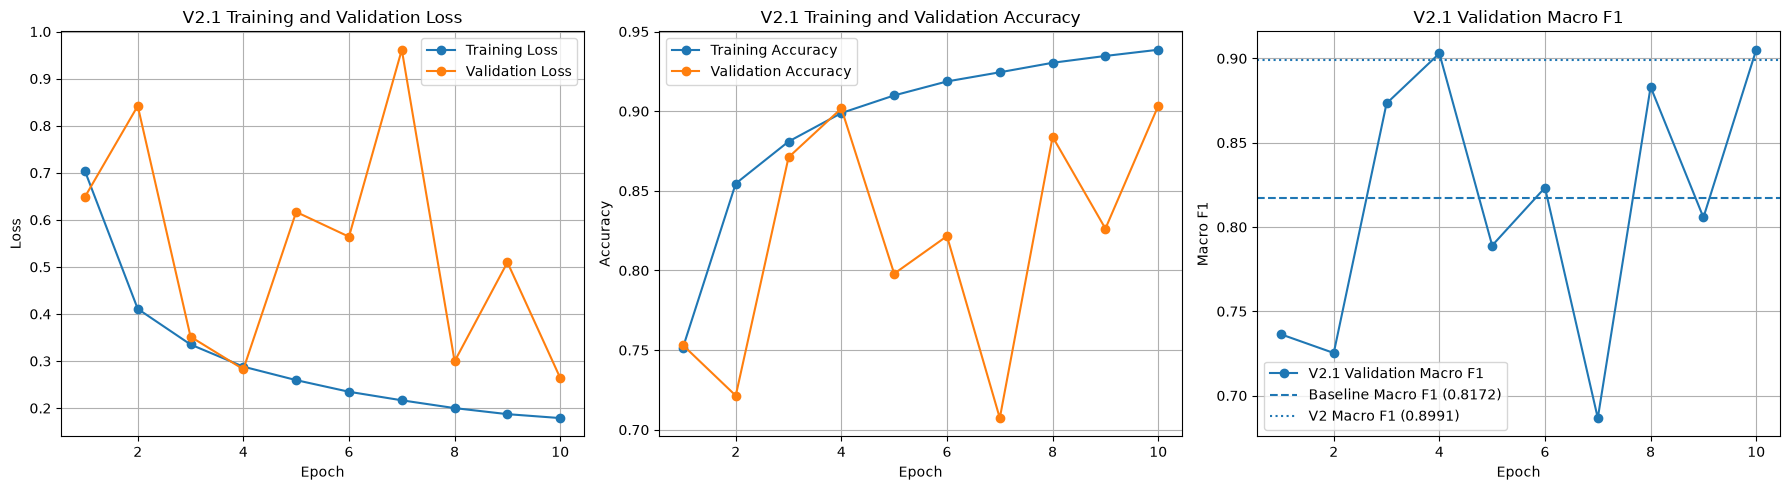

V2.1 learning curves saved successfully!


In [46]:
# Convert training history into a DataFrame
history_v21_df = pd.DataFrame(history_v21)

epochs = history_v21_df["epoch"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Loss
axes[0].plot(epochs, history_v21_df["train_loss"],
             marker="o", label="Training Loss")
axes[0].plot(epochs, history_v21_df["val_loss"],
             marker="o", label="Validation Loss")
axes[0].set_title("V2.1 Training and Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

# 2. Accuracy
axes[1].plot(epochs, history_v21_df["train_accuracy"],
             marker="o", label="Training Accuracy")
axes[1].plot(epochs, history_v21_df["val_accuracy"],
             marker="o", label="Validation Accuracy")
axes[1].set_title("V2.1 Training and Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True)

# 3. Macro F1
axes[2].plot(epochs, history_v21_df["val_macro_f1"],
             marker="o", label="V2.1 Validation Macro F1")
axes[2].axhline(
    y=0.8172,
    linestyle="--",
    label="Baseline Macro F1 (0.8172)"
)
axes[2].axhline(
    y=0.8991,
    linestyle=":",
    label="V2 Macro F1 (0.8991)"
)
axes[2].set_title("V2.1 Validation Macro F1")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("Macro F1")
axes[2].legend()
axes[2].grid(True)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "v2_1_learning_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("V2.1 learning curves saved successfully!")

In [47]:
model_v21.eval()

all_predictions_v21 = []
all_labels_v21 = []

with torch.no_grad():
    for images, labels in val_loader:

        images = images.to(device)

        outputs = model_v21(images)

        predictions = torch.argmax(outputs, dim=1)

        all_predictions_v21.extend(
            predictions.cpu().numpy()
        )

        all_labels_v21.extend(
            labels.numpy()
        )

all_predictions_v21 = np.array(all_predictions_v21)
all_labels_v21 = np.array(all_labels_v21)

print("Validation predictions completed!")
print("Total predictions:", len(all_predictions_v21))
print("Total actual labels:", len(all_labels_v21))

print(
    "Validation Accuracy:",
    f"{accuracy_score(all_labels_v21, all_predictions_v21):.4f}"
)

print(
    "Validation Macro F1:",
    f"{f1_score(all_labels_v21, all_predictions_v21, average='macro'):.4f}"
)

Validation predictions completed!
Total predictions: 10004
Total actual labels: 10004
Validation Accuracy: 0.9033
Validation Macro F1: 0.9052


In [48]:
report_v21 = classification_report(
    all_labels_v21,
    all_predictions_v21,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

report_v21_df = pd.DataFrame(report_v21).transpose()

print(
    report_v21_df.round(4).to_string()
)

report_v21_df.to_csv(
    PROJECT_ROOT / "docs" / "v2_1_validation_classification_report.csv"
)

print("\nClassification report saved successfully!")

                                      precision  recall  f1-score     support
Adipose                                  0.9187  0.9981    0.9567   1041.0000
Background                               0.9803  0.9896    0.9849   1057.0000
Debris                                   0.7543  0.9193    0.8286   1152.0000
Lymphocytes                              1.0000  0.9576    0.9783   1156.0000
Mucus                                    0.9658  0.7921    0.8704    890.0000
Smooth Muscle                            0.9526  0.8914    0.9210   1354.0000
Normal Colon Mucosa                      0.9105  0.9396    0.9248    877.0000
Cancer-associated Stroma                 0.7488  0.9043    0.8192   1045.0000
Colorectal Adenocarcinoma Epithelium     0.9770  0.7716    0.8623   1432.0000
accuracy                                 0.9033  0.9033    0.9033      0.9033
macro avg                                0.9120  0.9071    0.9052  10004.0000
weighted avg                             0.9143  0.9033    0.904

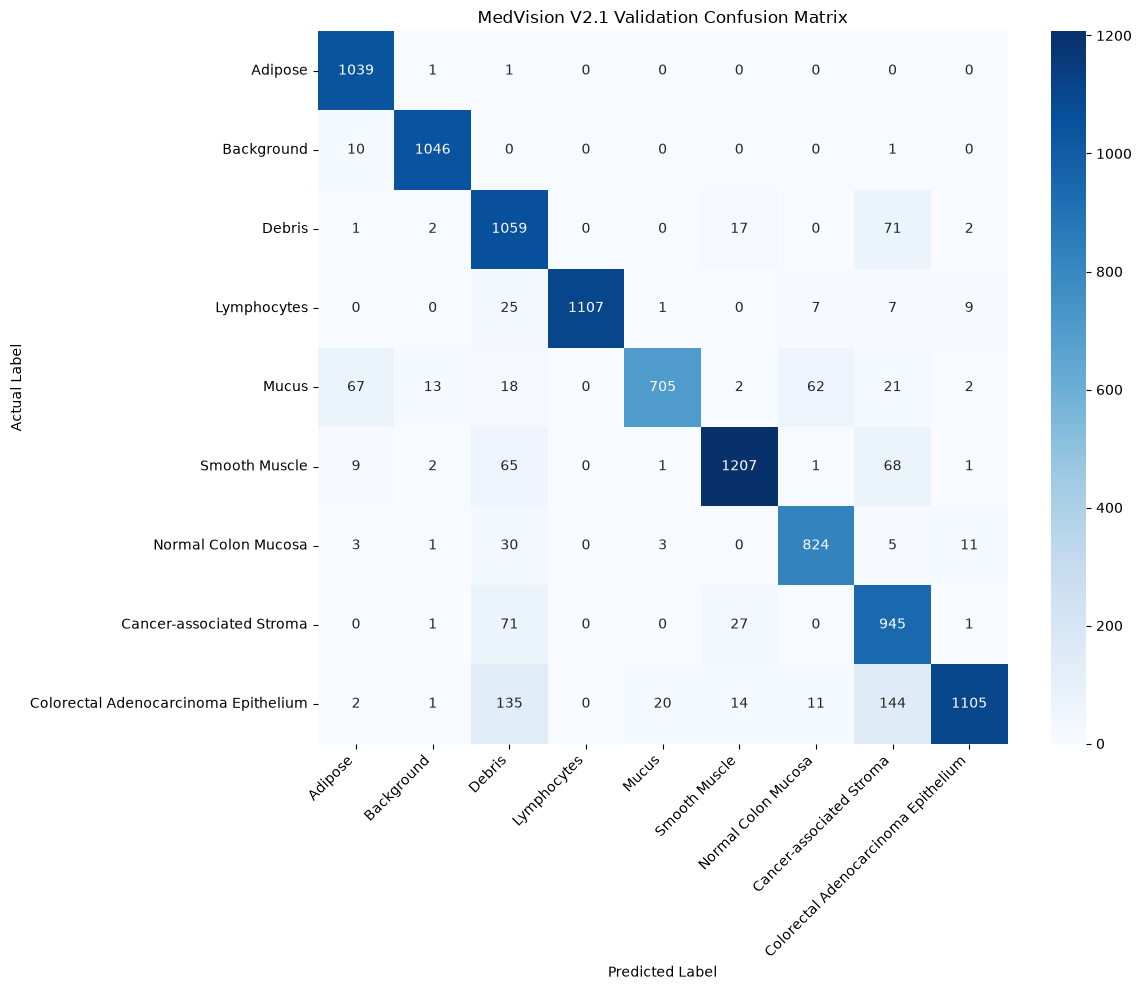

V2.1 confusion matrix saved successfully!


In [49]:
cm_v21 = confusion_matrix(
    all_labels_v21,
    all_predictions_v21
)

plt.figure(figsize=(12, 10))

sns.heatmap(
    cm_v21,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("MedVision V2.1 Validation Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "v2_1_validation_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Save raw confusion matrix
cm_v21_df = pd.DataFrame(
    cm_v21,
    index=class_names,
    columns=class_names
)

cm_v21_df.to_csv(
    PROJECT_ROOT / "docs" / "v2_1_validation_confusion_matrix.csv"
)

print("V2.1 confusion matrix saved successfully!")

                               Class  Baseline F1  V2.1 F1  Improvement
                             Adipose       0.9394   0.9567       0.0173
                          Background       0.9565   0.9849       0.0284
                              Debris       0.7023   0.8286       0.1263
                         Lymphocytes       0.9336   0.9783       0.0447
                               Mucus       0.7915   0.8704       0.0789
                       Smooth Muscle       0.7946   0.9210       0.1264
                 Normal Colon Mucosa       0.7291   0.9248       0.1957
            Cancer-associated Stroma       0.6606   0.8192       0.1586
Colorectal Adenocarcinoma Epithelium       0.8468   0.8623       0.0155


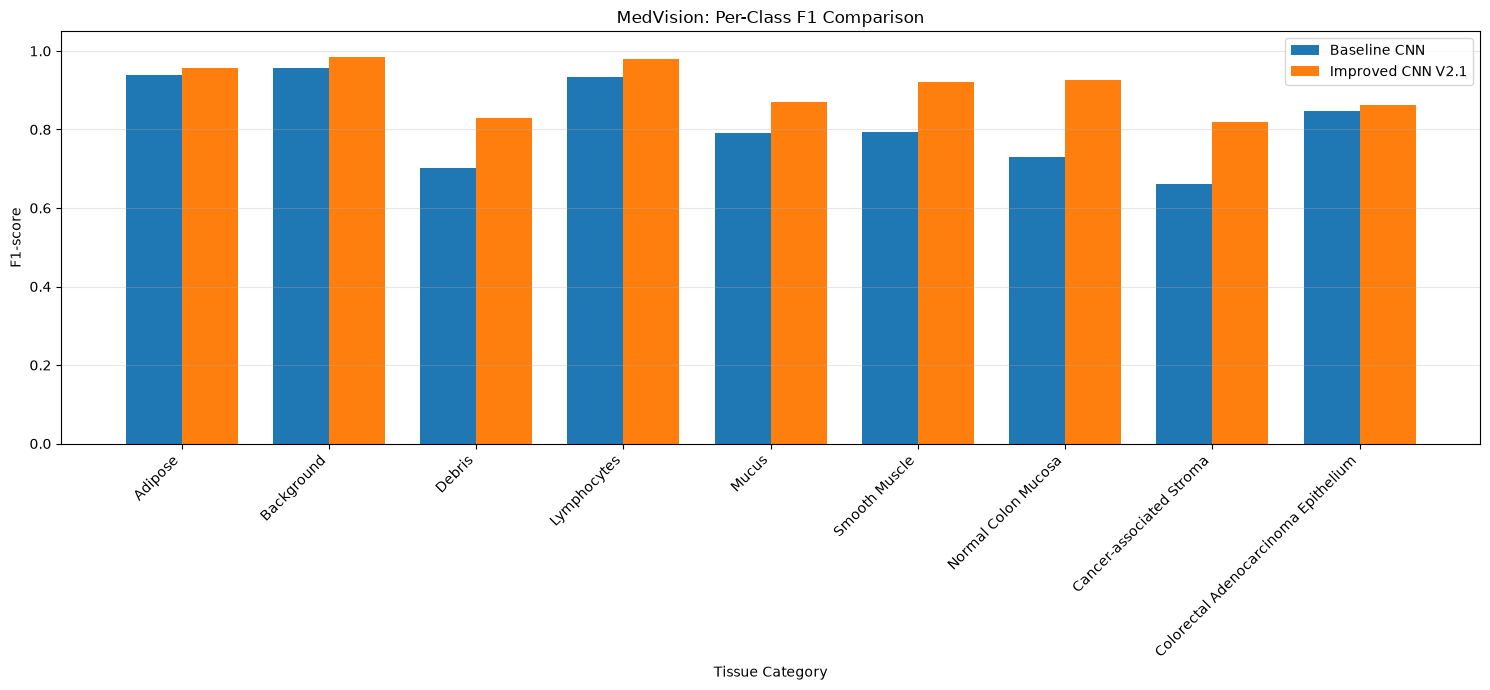

Model comparison chart saved successfully!


In [50]:
baseline_f1 = [
    0.9394, 0.9565, 0.7023,
    0.9336, 0.7915, 0.7946,
    0.7291, 0.6606, 0.8468
]

v21_f1 = [
    0.9567, 0.9849, 0.8286,
    0.9783, 0.8704, 0.9210,
    0.9248, 0.8192, 0.8623
]

comparison_df = pd.DataFrame({
    "Class": class_names,
    "Baseline F1": baseline_f1,
    "V2.1 F1": v21_f1
})

comparison_df["Improvement"] = (
    comparison_df["V2.1 F1"] -
    comparison_df["Baseline F1"]
)

print(comparison_df.round(4).to_string(index=False))

# Plot comparison
x = np.arange(len(class_names))
width = 0.38

fig, ax = plt.subplots(figsize=(15, 7))

ax.bar(
    x - width / 2,
    comparison_df["Baseline F1"],
    width,
    label="Baseline CNN"
)

ax.bar(
    x + width / 2,
    comparison_df["V2.1 F1"],
    width,
    label="Improved CNN V2.1"
)

ax.set_title("MedVision: Per-Class F1 Comparison")
ax.set_xlabel("Tissue Category")
ax.set_ylabel("F1-score")
ax.set_xticks(x)
ax.set_xticklabels(class_names, rotation=45, ha="right")
ax.set_ylim(0, 1.05)
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "baseline_vs_v21_class_f1.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Model comparison chart saved successfully!")


In [51]:
# Load the selected best V2.1 checkpoint
model_v21.load_state_dict(
    torch.load(
        MODEL_PATH_V21,
        map_location=device,
        weights_only=True
    )
)

model_v21.eval()

print("Final V2.1 checkpoint loaded successfully!")
print("Model:", model_v21.__class__.__name__)
print("Checkpoint:", MODEL_PATH_V21)

Final V2.1 checkpoint loaded successfully!
Model: MedVisionCNNV2
Checkpoint: /Users/keonhowang/Desktop/MedVision/models/medvision_cnn_v2_lr0003.pth


In [52]:
all_test_predictions_v21 = []
all_test_labels_v21 = []

model_v21.eval()

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = model_v21(images)

        predictions = torch.argmax(outputs, dim=1)

        all_test_predictions_v21.extend(
            predictions.cpu().numpy()
        )

        all_test_labels_v21.extend(
            labels.numpy()
        )

all_test_predictions_v21 = np.array(
    all_test_predictions_v21
)

all_test_labels_v21 = np.array(
    all_test_labels_v21
)

print("Final test predictions completed!")
print("Total test predictions:", len(all_test_predictions_v21))
print("Total actual labels:", len(all_test_labels_v21))

Final test predictions completed!
Total test predictions: 7180
Total actual labels: 7180


In [53]:
test_accuracy_v21 = accuracy_score(
    all_test_labels_v21,
    all_test_predictions_v21
)

test_macro_f1_v21 = f1_score(
    all_test_labels_v21,
    all_test_predictions_v21,
    average="macro"
)

test_weighted_f1_v21 = f1_score(
    all_test_labels_v21,
    all_test_predictions_v21,
    average="weighted"
)

print("MedVision V2.1 - Final Test Results")
print("-----------------------------------")
print(f"Test Accuracy:    {test_accuracy_v21:.4f}")
print(f"Test Macro F1:     {test_macro_f1_v21:.4f}")
print(f"Test Weighted F1:  {test_weighted_f1_v21:.4f}")

MedVision V2.1 - Final Test Results
-----------------------------------
Test Accuracy:    0.7710
Test Macro F1:     0.7334
Test Weighted F1:  0.7793


In [54]:
test_report_v21 = classification_report(
    all_test_labels_v21,
    all_test_predictions_v21,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

test_report_v21_df = pd.DataFrame(
    test_report_v21
).transpose()

print(
    test_report_v21_df.round(4).to_string()
)

test_report_v21_df.to_csv(
    PROJECT_ROOT / "docs" /
    "v2_1_test_classification_report.csv"
)

print("\nFinal test classification report saved!")

                                      precision  recall  f1-score   support
Adipose                                  0.8183  0.9694    0.8874  1338.000
Background                               0.8036  1.0000    0.8911   847.000
Debris                                   0.2967  0.7965    0.4323   339.000
Lymphocytes                              0.9767  0.5946    0.7392   634.000
Mucus                                    0.9508  0.5420    0.6905  1035.000
Smooth Muscle                            0.7381  0.6807    0.7083   592.000
Normal Colon Mucosa                      0.8701  0.8138    0.8410   741.000
Cancer-associated Stroma                 0.5538  0.5748    0.5641   421.000
Colorectal Adenocarcinoma Epithelium     0.9561  0.7591    0.8463  1233.000
accuracy                                 0.7710  0.7710    0.7710     0.771
macro avg                                0.7738  0.7479    0.7334  7180.000
weighted avg                             0.8319  0.7710    0.7793  7180.000

Final test 

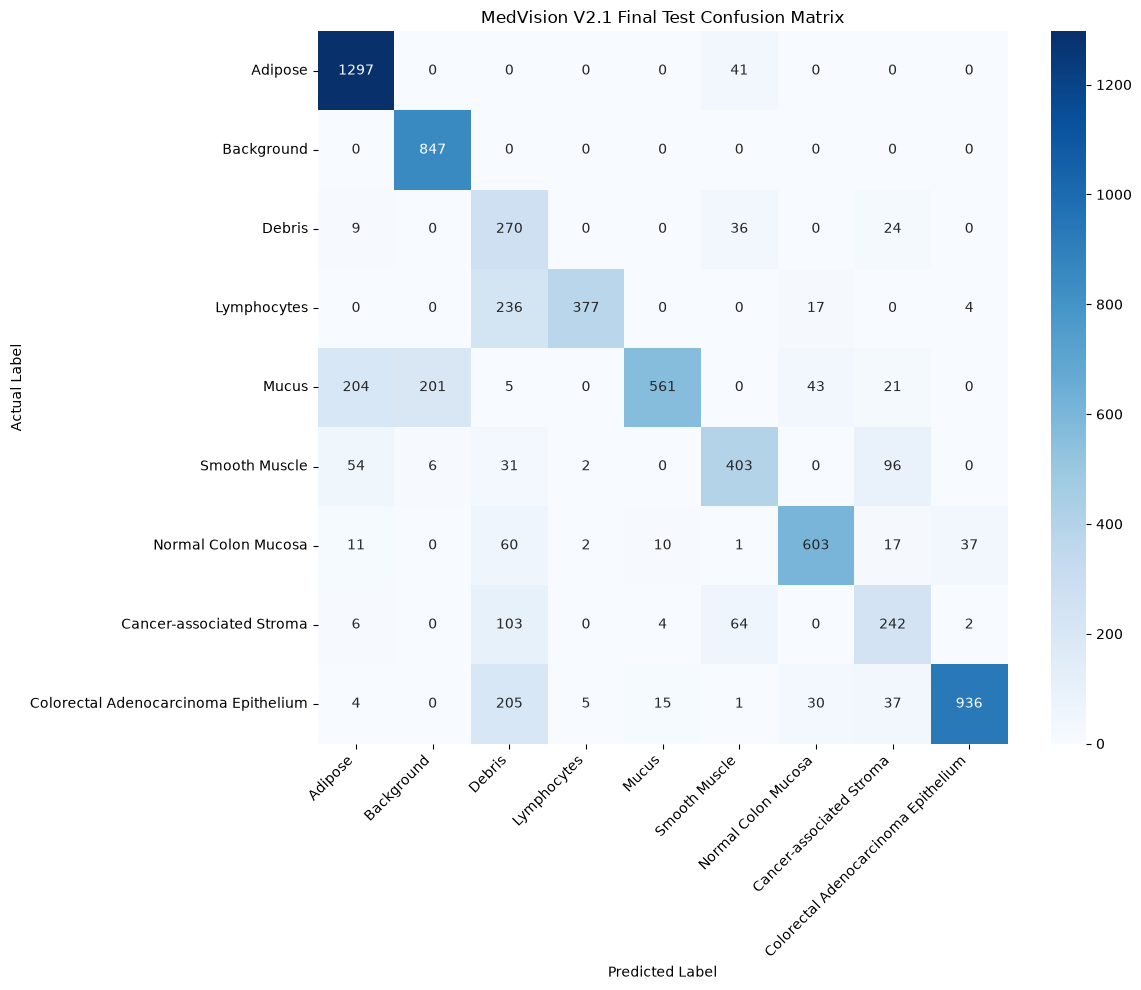

Final test confusion matrix saved!


In [55]:
cm_test_v21 = confusion_matrix(
    all_test_labels_v21,
    all_test_predictions_v21
)

plt.figure(figsize=(12, 10))

sns.heatmap(
    cm_test_v21,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("MedVision V2.1 Final Test Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "v2_1_test_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

cm_test_v21_df = pd.DataFrame(
    cm_test_v21,
    index=class_names,
    columns=class_names
)

cm_test_v21_df.to_csv(
    PROJECT_ROOT / "docs" /
    "v2_1_test_confusion_matrix.csv"
)

print("Final test confusion matrix saved!")

In [56]:
final_comparison = pd.DataFrame({
    "Model": [
        "Baseline CNN",
        "Improved CNN V2",
        "Improved CNN V2.1"
    ],
    "Validation Macro F1": [
        0.8172,
        0.8991,
        0.9052
    ],
    "Test Accuracy": [
        0.8006,
        np.nan,
        0.7710
    ],
    "Test Macro F1": [
        0.7354,
        np.nan,
        0.7334
    ],
    "Test Weighted F1": [
        0.8021,
        np.nan,
        0.7793
    ]
})

print(final_comparison.round(4).to_string(index=False))

final_comparison.to_csv(
    PROJECT_ROOT / "docs" / "final_model_comparison.csv",
    index=False
)

print("\nFinal model comparison saved successfully!")

            Model  Validation Macro F1  Test Accuracy  Test Macro F1  Test Weighted F1
     Baseline CNN               0.8172         0.8006         0.7354            0.8021
  Improved CNN V2               0.8991            NaN            NaN               NaN
Improved CNN V2.1               0.9052         0.7710         0.7334            0.7793

Final model comparison saved successfully!


In [57]:
results_content = """
# MedVision — Experimental Results

## 1. Project Overview

MedVision is an educational deep learning project for multi-class
histopathology image classification using the PathMNIST dataset.

The system classifies images into nine tissue categories using
Convolutional Neural Networks (CNNs) implemented with PyTorch.

This project is intended for educational and research purposes only.
It is not a clinically validated diagnostic system.

## 2. Dataset

Dataset: PathMNIST (MedMNIST)

- Training samples: 89,996
- Validation samples: 10,004
- Test samples: 7,180
- Total samples: 107,180
- Image dimensions: 28 x 28 pixels
- Image channels: 3 (RGB)
- Number of classes: 9

Training and validation data originate from NCT-CRC-HE-100K.
The independent test set originates from CRC-VAL-HE-7K.

The separate test source provides an opportunity to examine
generalization across different data sources.

## 3. Model Experiments

### 3.1 Baseline CNN

The baseline model was developed from scratch using PyTorch.

Architecture:
- Convolutional layer: 3 to 32 channels
- ReLU activation
- Max pooling
- Convolutional layer: 32 to 64 channels
- ReLU activation
- Max pooling
- Fully connected layer: 64 x 7 x 7 to 128
- Fully connected output layer: 128 to 9 classes

Trainable parameters: 422,089

Training configuration:
- Optimizer: Adam
- Learning rate: 0.001
- Loss: CrossEntropyLoss
- Epochs: 5
- Batch size: 64

### 3.2 Improved CNN V2

The second model introduced:
- Three convolutional layers
- Batch normalization
- Dropout (0.4)
- Adaptive average pooling
- Random horizontal and vertical flips
- Random right-angle rotations
- Inverse-frequency class weighting

Trainable parameters: 111,369

Training configuration:
- Optimizer: Adam
- Learning rate: 0.001
- Loss: Weighted CrossEntropyLoss
- Epochs: 10
- Batch size: 64

Best validation checkpoint: Epoch 6.

### 3.3 Improved CNN V2.1

V2.1 retained the V2 architecture and training strategy,
with a reduced learning rate.

Training configuration:
- Optimizer: Adam
- Learning rate: 0.0003
- Loss: Weighted CrossEntropyLoss
- Epochs: 10
- Batch size: 64

Best validation checkpoint: Epoch 10.

The purpose of this experiment was to investigate whether
a lower learning rate improved validation performance
and training stability.

## 4. Validation Results

| Model | Validation Accuracy | Validation Macro F1 |
|---|---:|---:|
| Baseline CNN | 82.04% | 81.72% |
| Improved CNN V2 | 90.28% | 89.91% |
| Improved CNN V2.1 | 90.33% | 90.52% |

V2.1 achieved the highest validation Macro F1.

Compared with the baseline, its validation Macro F1 improved
by approximately 8.80 percentage points.

## 5. Independent Test Results

| Model | Test Accuracy | Test Macro F1 | Test Weighted F1 |
|---|---:|---:|---:|
| Baseline CNN | 80.06% | 73.54% | 80.21% |
| Improved CNN V2 | Not evaluated | Not evaluated | Not evaluated |
| Improved CNN V2.1 | 77.10% | 73.34% | 77.93% |

V2.1 achieved a slightly lower independent test Macro F1
than the baseline, despite its substantially higher validation score.

The baseline achieved:
- Test accuracy: 80.06%
- Test Macro F1: 73.54%
- Test weighted F1: 80.21%

V2.1 achieved:
- Test accuracy: 77.10%
- Test Macro F1: 73.34%
- Test weighted F1: 77.93%

These findings show that stronger validation performance
did not translate into better overall independent test performance.

## 6. Per-Class Test Analysis

V2.1 improved the test F1-score for four categories compared
with the baseline:

- Debris: 31.68% to 43.23%
- Smooth Muscle: 61.03% to 70.83%
- Normal Colon Mucosa: 78.10% to 84.10%
- Cancer-associated Stroma: 50.65% to 56.41%

Five categories had lower test F1-scores:

- Adipose
- Background
- Lymphocytes
- Mucus
- Colorectal Adenocarcinoma Epithelium

Notable V2.1 test results:

- Background recall: 100.00%
- Adipose recall: 96.94%
- Debris recall: 79.65%
- Lymphocytes recall: 59.46%
- Mucus recall: 54.20%

The confusion matrix revealed substantial confusion between
Lymphocytes and Debris, and between Mucus and other tissue types.

## 7. Discussion

The validation and independent test results show a substantial
performance gap, particularly for V2.1.

One possible explanation is domain shift, because the training
and validation data originate from NCT-CRC-HE-100K, while the
independent test data originate from CRC-VAL-HE-7K.

Differences in staining, image acquisition, tissue appearance,
and data distributions may affect generalization.

However, the experiments do not establish the exact cause
of this performance gap.

The results also demonstrate why accuracy alone is insufficient.
Macro F1 and class-level precision and recall provide additional
insight into performance across all nine categories.

## 8. Conclusion

Three CNN experiments were developed and evaluated.

V2.1 achieved the strongest validation Macro F1 of 90.52%.
However, the baseline achieved the highest independent test
Macro F1 of 73.54%, compared with 73.34% for V2.1.

Therefore, V2.1 should not be described as the best
generalizing model based on the available test evidence.

The baseline remains the strongest model by overall
independent test Macro F1 in these experiments.

V2.1 demonstrates that architectural improvements,
augmentation, and class weighting can improve validation
performance, but they do not guarantee better generalization
to data from a different source.

## 9. Limitations

- The models use low-resolution 28 x 28 images.
- Only three CNN configurations were investigated.
- The independent test performance remains limited.
- The test set comes from a different source, and the exact
  causes of the performance gap have not been established.
- No external clinical validation was performed.
- Model predictions must not be used for medical diagnosis
  or treatment decisions.

## 10. Dataset and References

- MedMNIST: https://medmnist.com/
- MedMNIST GitHub: https://github.com/MedMNIST/MedMNIST
- MedMNIST paper: https://doi.org/10.1038/s41597-022-01721-8

Dataset license: CC BY 4.0.
"""

RESULTS_PATH = PROJECT_ROOT / "docs" / "RESULTS.md"

RESULTS_PATH.write_text(
    results_content.strip() + "\\n",
    encoding="utf-8"
)

print("Results documentation created successfully!")
print("File:", RESULTS_PATH)
print("Size:", RESULTS_PATH.stat().st_size, "bytes")

Results documentation created successfully!
File: /Users/keonhowang/Desktop/MedVision/docs/RESULTS.md
Size: 6018 bytes
